# Classify using DTW on stretched spike first deriv.

In [1]:
cut_params = {
    'signal_name': 'wideband',
    'event_name': 'spk',
    'cut_window': [-0.001, 0.002],
    'fs': 40000
}
proc_params = {
    'smooth_params': {
        'window_length': 9,
        'polyorder': 3
    },
    'dv_threshold': 0.1
}

In [2]:
import os

INVITRO_DATA_DIR = f'{os.environ["RAAP_INVITRO_DATA"]}/juxta'
INVIVO_DATA_DIR = f'{os.environ["RAAP_INVIVO_DATA"]}'
INVIVO_FEATURE_DIR = f'{os.environ["RAAP_INVIVO_FEATURES"]}'

In [3]:
training_cell_names = [
    '2406241PZ_01',
    '2406242PZ_03',
    '2406263PZ_01',
    '2406282PZ_01',
    '2407031PZ_01',
    '2407031SI_gr2',
    '2407041SI_gr1'
]

In [4]:
from workflow import load_training_dataset
training_dataset = load_training_dataset(
    training_cell_names,
    INVITRO_DATA_DIR,
    cut_params=cut_params,
    proc_params=proc_params
)

In [5]:
from transformers import (
    FirstDeriv,
    rising_phase,
    first_derivative,
    resample_first_deriv,
    normalize_first_deriv
)
test_ais = training_dataset[0]['AISAP'][0]
test_ra = training_dataset[0]['RAAP'][0]
ais_deriv = first_derivative(rising_phase(test_ais, start=0.15, end=0.85))
ra_deriv = first_derivative(rising_phase(test_ra, start=0.15, end=0.85))
ais_deriv_norm = normalize_first_deriv(ais_deriv)
ra_deriv_norm = normalize_first_deriv(ra_deriv)
ais_deriv_resampled = resample_first_deriv(ais_deriv_norm, 20)
ra_deriv_resampled = resample_first_deriv(ra_deriv_norm, 20)

In [6]:
from dtw import dtw
raw_alignment = dtw(
    ais_deriv.dv,
    ra_deriv.dv,
    dist_method='euclidean'
)
norm_alignment = dtw(
    ais_deriv_norm.dv,
    ra_deriv_norm.dv,
    dist_method='euclidean'
)
resampled_alignment = dtw(
    ais_deriv_resampled.dv,
    ra_deriv_resampled.dv,
    dist_method='euclidean'
)
unnorm_dist = getattr(raw_alignment, 'distance')
norm_dist = getattr(norm_alignment, 'normalizedDistance')
resampled_dist = getattr(resampled_alignment, 'distance')
print(f'Unnormalized DTW distance: {unnorm_dist}')
print(f'Normalized DTW distance: {norm_dist}')
print(f'Resampled DTW distance: {resampled_dist}')

Importing the dtw module. When using in academic works please cite:
  T. Giorgino. Computing and Visualizing Dynamic Time Warping Alignments in R: The dtw Package.
  J. Stat. Soft., doi:10.18637/jss.v031.i07.

Unnormalized DTW distance: 0.3545347799240267
Normalized DTW distance: 0.10666680557747026
Resampled DTW distance: 3.61235175568921


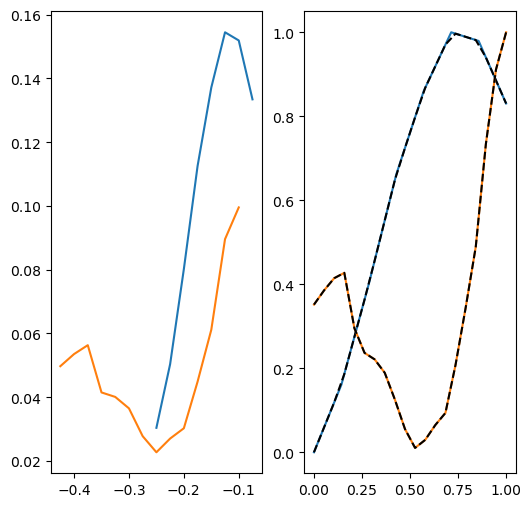

In [7]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(6, 6))
axes[0].plot(
    ais_deriv.times,
    ais_deriv.dv,
    color='C0'
)
axes[0].plot(
    ra_deriv.times,
    ra_deriv.dv,
    color='C1'
)
axes[1].plot(
    ais_deriv_norm.times,
    ais_deriv_norm.dv,
    color='C0'
)
axes[1].plot(
    ais_deriv_resampled.times,
    ais_deriv_resampled.dv,
    '--',
    color='black'
)
axes[1].plot(
    ra_deriv_resampled.times,
    ra_deriv_resampled.dv,
    color='C1'
)
axes[1].plot(
    ra_deriv_resampled.times,
    ra_deriv_resampled.dv,
    '--',
    color='black'
)
plt.show()

In [8]:
import numpy as np
n_training_samples = len(training_dataset)
derivs, y = [], []
for i, spike_type in enumerate(['AISAP', 'RAAP']):
    for cell_shapes in training_dataset:
        for spike in cell_shapes[spike_type]:
            deriv = resample_first_deriv(
                normalize_first_deriv(
                    first_derivative(
                        rising_phase(spike)
                    )
                ), 20
            )
            derivs.append(deriv)
            y.append(i)
y = np.array(y)
n_spikes = len(derivs)

In [9]:
from tqdm import tqdm
D = np.zeros((n_spikes, n_spikes))
for i in tqdm(range(n_spikes), total=n_spikes):
    for j in range(i + 1, n_spikes):
        alignment = dtw(
            derivs[i].dv,
            derivs[j].dv,
            dist_method='euclidean'
        )
        D[i, j] = getattr(alignment, 'distance')
        D[j, i] = D[i, j]

100%|██████████| 1453/1453 [04:33<00:00,  5.31it/s] 


In [10]:
group_mean_curves = []
for yy in [0, 1]:
    group_curves = [curve for curve, label in zip(derivs, y) if label == yy]
    group_mean_curves.append(
        normalize_first_deriv(FirstDeriv(
            np.mean([curve.times for curve in group_curves], axis=0),
            np.mean([curve.dv for curve in group_curves], axis=0)
        ))
    )

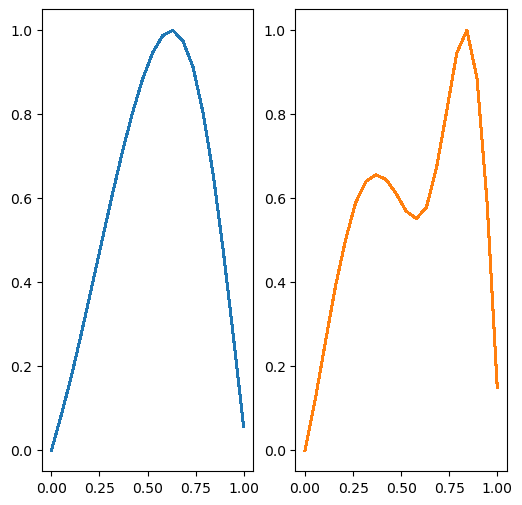

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(6, 6))
for deriv, label in zip(derivs, y):
    axes[label].plot(
        group_mean_curves[label].times,
        group_mean_curves[label].dv,
        color='C0' if label == 0 else 'C1',
        alpha=0.3
    )
plt.show()

In [18]:
template_alignment = dtw(
    group_mean_curves[0].dv,
    group_mean_curves[1].dv,
    dist_method='euclidean',
    keep_internals=True
)
print(f'Template DTW distance: {getattr(template_alignment, "distance")}')

Template DTW distance: 1.3889245269423005


<Axes: xlabel='Index', ylabel='Query value'>

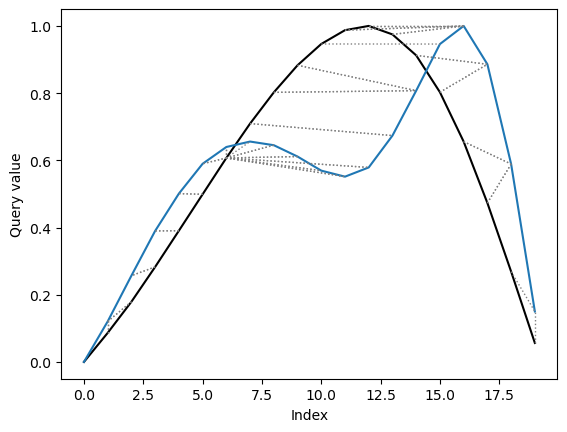

In [19]:
template_alignment.plot(type="twoway")

In [12]:
import pandas as pd
D_from_mean = np.zeros((n_spikes, 2))
for i, deriv in tqdm(enumerate(derivs), total=n_spikes):
    for yy in [0, 1]:
        alignment = dtw(
            deriv.dv,
            group_mean_curves[yy].dv,
            dist_method='euclidean'
        )
        D_from_mean[i, yy] = getattr(alignment, 'distance')

mean_dist_df = pd.DataFrame(np.stack([D_from_mean[:, 0], D_from_mean[:, 1], y], axis=1), columns=['AISAP', 'RAAP', 'Label'])
mean_dist_df['id'] = mean_dist_df.index
mean_dist_df['pref'] = (
    mean_dist_df['AISAP'] - mean_dist_df['RAAP']
) / (
    mean_dist_df['AISAP'] + mean_dist_df['RAAP']
)

100%|██████████| 1453/1453 [00:00<00:00, 2298.34it/s]


In [29]:
closest_ais_self = mean_dist_df[mean_dist_df['Label'] == 0]['AISAP'].argmin()
farthest_ais_self = mean_dist_df[mean_dist_df['Label'] == 0]['AISAP'].argmax()
closest_ra_self = mean_dist_df[mean_dist_df['Label'] == 1]['AISAP'].argmin()
farthest_ra_self = mean_dist_df[mean_dist_df['Label'] == 1]['AISAP'].argmax()

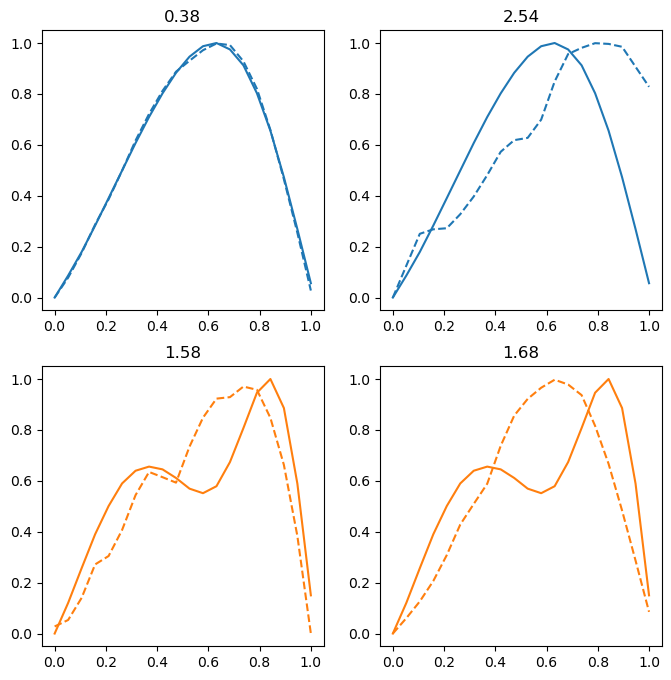

In [31]:
fig, axes = plt.subplots(2, 2, figsize=(8, 8))
colors = {
    'AISAP': 'C0',
    'RAAP': 'C1'
}
close_indices = [
    [closest_ais_self, farthest_ais_self],
    [closest_ra_self, farthest_ra_self]
]
for i, (spike_type, group_curve, members) in enumerate(zip(['AISAP', 'RAAP'], group_mean_curves, close_indices)):
    for j, idx in enumerate(members):
        axes[i, j].plot(
            group_curve.times,
            group_curve.dv,
            color=colors[spike_type]
        )
        axes[i, j].plot(
            derivs[idx].times,
            derivs[idx].dv,
            '--',
            color=colors[spike_type]
        )
        axes[i, j].set_title(
            f'{mean_dist_df.iloc[idx][spike_type]:.2f}'
        )

plt.show()

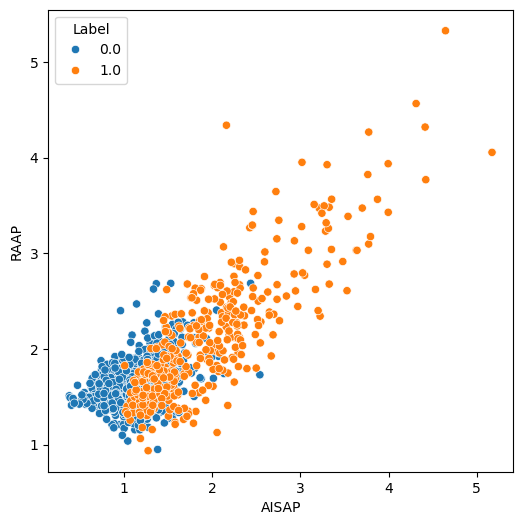

In [14]:
import seaborn as sns
fig, ax = plt.subplots(figsize=(6, 6))
sns.scatterplot(
    data=mean_dist_df,
    x='AISAP',
    y='RAAP',
    hue='Label',
    ax=ax
)
plt.show()